# EN3160 Image Processing and Machine Vision
## Assignment 3: Neural Networks
GUNATHUNGA U.A.  
230218G  
[GitHub repository](https://github.com/Upani-Gunathunga/EN3160-A3-Neural-Networks)


In [1]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time
import copy
from pathlib import Path
from IPython.display import display, Markdown
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

output_path = Path('results')
output_path.mkdir(exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
np.random.seed(42)
print('Device:', device)
print('PyTorch:', torch.__version__)
print('Torchvision:', torchvision.__version__)
print('Working folder:', Path.cwd())


Device: cuda
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Working folder: c:\Users\asus\Documents\semester 5\CV\ass3


## QUESTION 1
### Important parts of code

The complete Question 1 follows the six sections of Listing 1 with below changes.

| Change | Meaning |
|---|---|
| Middle layer | $3072\rightarrow100\rightarrow10$. Weight shapes are $3072\times100$ and $100\times10$. |
| Sigmoid | Apply $1/(1+e^{-z})$ to the 100 hidden values. |
| Cross-entropy | Use softmax class probabilities and $L=-\frac1N\sum_i\log P_{i,y_i}$. `log_softmax` computes the log probabilities directly. |
| Backpropagation | The output gradient is $(P-Y)/N$. The hidden gradient also includes the sigmoid derivative $a(1-a)$. Compute all gradients before updating weights. |
| Epoch count | Change 20 to 10. Final accuracies use the weights after epoch 10. |


Weight initialization uses standard deviation $1/\sqrt{\text{input count}}$. The learning rate is 0.1 with decay 0.9.


Device: cuda
Epoch 1/10, Loss: 1.8062101985216141
Epoch 2/10, Loss: 1.6728562210798263
Epoch 3/10, Loss: 1.6113708715438844
Epoch 4/10, Loss: 1.566626722574234
Epoch 5/10, Loss: 1.5266632050275804
Epoch 6/10, Loss: 1.491914845585823
Epoch 7/10, Loss: 1.463333183646202
Epoch 8/10, Loss: 1.4365388722419739
Epoch 9/10, Loss: 1.4133375564813613
Epoch 10/10, Loss: 1.3922812718749047


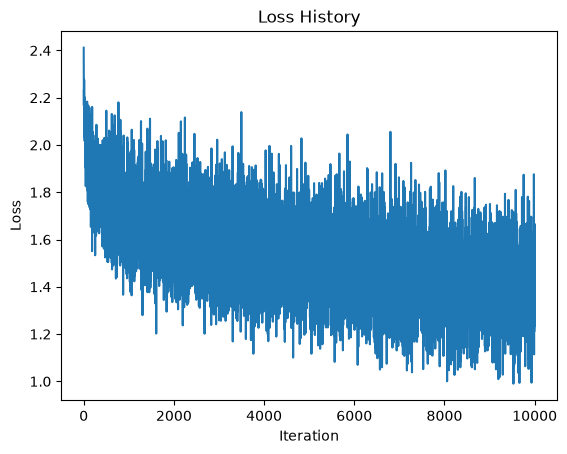

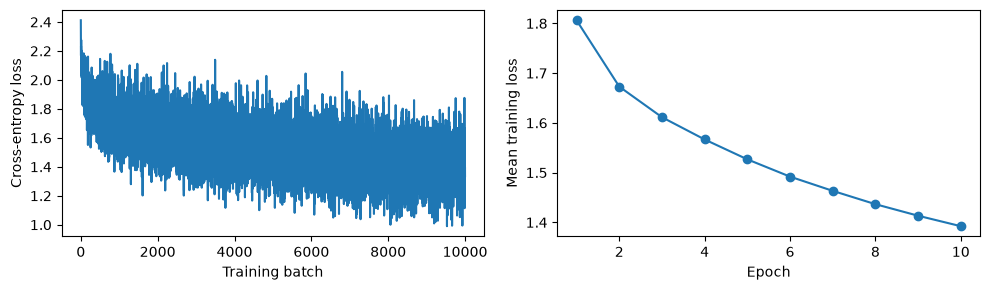

Training accuracy: 53.45%
Test accuracy: 47.77%


In [2]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
print('Device:', device)

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-5         # Initialize weights and biases

# w = torch.randn(Din, K) * std  # One layer: directly map input to output
# b = torch.zeros(K)
########################################

H = 100
# Initialize weights and biases
w1 = torch.randn(Din, H, device=device) / (Din ** 0.5)
b1 = torch.zeros(H, device=device)
w2 = torch.randn(H, K, device=device) / (H ** 0.5)
b2 = torch.zeros(K, device=device)
##########################################

# Hyperparameters
iterations = 10
lr =   0.1     # Learning rate
lr_decay = 0.9     # Learning rate decay
reg = 0            # Regularization
loss_history = []
epoch_losses = []


# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data

        #-----------move batch to device----------
        inputs = inputs.to(device)
        labels = labels.to(device)
        #--------------end-----------------------


        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()  # Convert labels to one-hot

        ############### middle layer and sigmoid activation  #######
    
        
        # Forward pass
        # y_pred = x_train.mm(w) + b  # Output layer activation

        hidden_input = x_train.mm(w1) + b1
        hidden = torch.sigmoid(hidden_input)
        y_pred = hidden.mm(w2) + b2
        log_probs = torch.log_softmax(y_pred, dim=1)
        
        # Loss calculation (log likelihood with regularization)
       
        loss = -(y_train_onehot * log_probs).sum() / Ntr
        loss = loss + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))

        loss_history.append(loss.item())
        running_loss += loss.item()
        
        # Backpropagation
        # dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        # dw = x_train.t().mm(dy_pred) + reg * w
        # db = dy_pred.sum(dim=0)
        
        # # Parameter update
        # w -= lr * dw
        # b -= lr * db


        # Backpropagation
        probs = log_probs.exp()
        dy_pred = (probs - y_train_onehot) / Ntr
        dw2 = hidden.t().mm(dy_pred) + 2 * reg * w2
        db2 = dy_pred.sum(dim=0)
        d_hidden = dy_pred.mm(w2.t())
        d_hidden_input = d_hidden * hidden * (1 - hidden)
        dw1 = x_train.t().mm(d_hidden_input) + 2 * reg * w1
        db1 = d_hidden_input.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2
        #-----------------------

        
    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")
    epoch_losses.append(running_loss / len(trainloader))
    
    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 4. Plotting the Loss History
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].plot(loss_history)
axes[0].set_xlabel('Training batch')
axes[0].set_ylabel('Cross-entropy loss')

axes[1].plot(range(1, iterations + 1), epoch_losses, marker='o')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Mean training loss')

plt.tight_layout()
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device)
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()
        
        # Forward pass
        #-----------middle layer and sigmoid activation----------
        hidden_input = x_train.mm(w1) + b1
        hidden = torch.sigmoid(hidden_input)
        y_train_pred = hidden.mm(w2) + b2
        #--------------end------------------------

        #_train_pred = x_train.mm(w) + b
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device)
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()
        
        # Forward pass
        #-----------middle layer and sigmoid activation----------
        hidden_input = x_test.mm(w1) + b1
        hidden = torch.sigmoid(hidden_input)
        y_test_pred = hidden.mm(w2) + b2
        #--------------end------------------------

        #_test_pred = x_test.mm(w) + b
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")


In [3]:
#-----------results and comparison----------
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

output_path = Path('results')
output_path.mkdir(exist_ok=True)
q1_results = pd.DataFrame({
    'Split': ['Training', 'Test'],
    'Correct': [correct_train, correct_test],
    'Total': [total_train, total_test],
    'Accuracy (%)': [train_acc, test_acc]
})
display(q1_results)
q1_results.to_csv(output_path / 'q1_results.csv', index=False)
pd.DataFrame({'epoch': range(1, iterations + 1), 'loss': epoch_losses}).to_csv(
    output_path / 'q1_epoch_losses.csv', index=False)
gap = train_acc - test_acc
display(Markdown(
    f'After {iterations} epochs, training accuracy is {train_acc:.2f}% and '
    f'test accuracy is {test_acc:.2f}%.  \n'
    f'The train minus test gap is {gap:.2f} percentage points.  \n'
    f'Mean training-batch loss changed from {epoch_losses[0]:.4f} '
    f'to {epoch_losses[-1]:.4f}.'))
#--------------end------------------------

,Split,Correct,Total,Accuracy (%)
0,Training,26724,50000,53.448
1,Test,4777,10000,47.770


After 10 epochs, training accuracy is 53.45% and test accuracy is 47.77%.  
The train minus test gap is 5.68 percentage points.  
Mean training-batch loss changed from 1.8062 to 1.3923.

### Image results and comparison of results
The plot shows cross-entropy after each training batch. An epoch is one complete pass through the training set.  
The table reports final training and test accuracies. A positive train minus test gap means the model classified the training images more accurately.  
The epoch loss averages batches while weights are being updated. The final accuracies are measured afterward with fixed weights.  
The sigmoid hidden layer allows nonlinear classification. Flattening the image does not explicitly preserve its two-dimensional layout.

## QUESTION 2
### Important parts of code
